# BFIN3003 - Artificial Intelligence and Financial Application

## Assessment 2: Impact of Different Machine Learning Algorithms on Bank Loan Approval

### East Midland Bank (EMB) — Loan Default Prediction

**Student Name:** Assem Zhanabay

**P Number:** P2772477

## Section 1: Exploratory Data Analysis (EDA)

1.1 Installing & Importing Libraries

In [ ]:
# Install gradient boosting libraries used in modern credit risk modelling
!pip install xgboost lightgbm  #Both are high-performance gradient boosting algorithms that is impotant for credit credit modelling

1.2 Import Libraries

In [ ]:
# Import numerical computation library
import numpy as np   # Used for numerical operations and arrays

# Import dataframe processing library
import pandas as pd  # Used for loading and manipulating datasets

# Import plotting libraries
import matplotlib.pyplot as plt   # Used to create charts and graphs
import seaborn as sns             # Used to create statistical visualizations

# Import dataset splitting tool
from sklearn.model_selection import train_test_split  # Splits dataset into training and testing sets

# Import machine learning models
from sklearn.linear_model import LogisticRegression   # Traditional credit scoring model
from sklearn.ensemble import RandomForestClassifier   # Tree-based ensemble model

# Import hyperparameter tuning tool
from sklearn.model_selection import GridSearchCV  # Searches for best model parameters

# Import advanced boosting models
from xgboost import XGBClassifier  # Gradient boosting algorithm optimized for speed
from lightgbm import LGBMClassifier  # Efficient gradient boosting used in finance

# Import evaluation metrics
from sklearn.metrics import accuracy_score  # Measures correct predictions
from sklearn.metrics import f1_score        # Measures balance between precision and recall
from sklearn.metrics import recall_score    # Measures ability to detect positive class
from sklearn.metrics import roc_auc_score   # Measures ranking ability of model
from sklearn.metrics import roc_curve       # Used for ROC curve visualization
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay  # Shows prediction errors

# Set random seed to ensure reproducibility
np.random.seed(42)

1.3 Loading the Dataset

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

In [ ]:
import pandas as pd

df = pd.read_csv('east_midlands.csv')
df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16,0,36369,41.8,25,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17,0,20131,53.3,27,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13,0,11987,92.2,26,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6,0,5472,21.5,13,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13,0,24584,69.8,43,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"


In [ ]:
path = 'east_midlands.csv'
df = pd.read_csv(path)
df.head()  # Shows first 5 rows to inspect dataset structure

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16,0,36369,41.8,25,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17,0,20131,53.3,27,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13,0,11987,92.2,26,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6,0,5472,21.5,13,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13,0,24584,69.8,43,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"


In [ ]:
df.tail()  # Shows last 5 rows to inspect dataset structure

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
396024,6000,36 months,13.11,202.49,B,B4,Michael's Arts & Crafts,5 years,RENT,64000.0,...,7,0,11456,97.1,9,w,INDIVIDUAL,0.0,0.0,"514 Cynthia Park Apt. 402\nWest Williamside, S..."
396025,10000,60 months,10.99,217.38,B,B4,licensed bankere,2 years,RENT,40000.0,...,6,0,1990,34.3,23,w,INDIVIDUAL,0.0,0.0,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,21000,36 months,12.29,700.42,C,C1,Agent,5 years,MORTGAGE,110000.0,...,6,0,43263,95.7,8,f,INDIVIDUAL,1.0,0.0,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,5000,36 months,9.99,161.32,B,B1,City Carrier,10+ years,RENT,56500.0,...,15,0,32704,66.9,23,f,INDIVIDUAL,0.0,0.0,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,21000,60 months,15.31,503.02,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,64000.0,...,9,0,15704,53.8,20,f,INDIVIDUAL,5.0,0.0,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [ ]:
df.shape

(396029, 27)

In [ ]:
# Check dataset dimensions
print(df.shape)  # Shows number of rows and columns

# Show column names
print(df.columns)  # Lists all dataset features

# Check missing values
print(df.isnull().sum())  # Displays number of missing values per column

(396029, 27)
Index(['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       'verification_status', 'issue_d', 'loan_status', 'purpose', 'title',
       'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'application_type',
       'mort_acc', 'pub_rec_bankruptcies', 'address'],
      dtype='object')
loan_amnt                   0
term                        0
int_rate                    0
installment                 0
grade                       0
sub_grade                   0
emp_title               22927
emp_length              18301
home_ownership              0
annual_inc                  0
verification_status         0
issue_d                     0
loan_status                 0
purpose                     0
title                    1756
dti                         0
earliest_cr_line            0
open_acc                    0
pub_

1.4 Data Cleaning — Handling Missing Values & Duplicates

In [ ]:
# Remove duplicate rows
print(f"Duplicates before: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Duplicates after: {df.duplicated().sum()}")

Duplicates before: 0
Duplicates after: 0


In [ ]:
# Fill missing values
df['emp_title'] = df['emp_title'].fillna('Unknown')
df['emp_length'] = df['emp_length'].fillna('Unknown')
df['mort_acc'] = df['mort_acc'].fillna(0)
df['pub_rec_bankruptcies'] = df['pub_rec_bankruptcies'].fillna(0)
df['revol_util'] = df['revol_util'].fillna(df['revol_util'].median())
df['title'] = df['title'].fillna('Unknown')

In [ ]:
# Confirm no missing values remain
print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values after cleaning:
Series([], dtype: int64)


1.5 Default vs Non-Default Distribution

The target variable is loan_status. Loans are classified as:

0 = Non-Default (Fully Paid)
1 = Default (Charged Off)

In [ ]:
# Keep only relevant loan statuses
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])]

In [ ]:
# Create binary target variable
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)

In [ ]:
# Print counts
counts = df['default'].value_counts()
pct = df['default'].value_counts(normalize=True) * 100
print(f"Non-Default (0): {counts[0]:,}  —  {pct[0]:.1f}%")
print(f"Default     (1): {counts[1]:,}  —  {pct[1]:.1f}%")

Non-Default (0): 318,356  —  80.4%
Default     (1): 77,673  —  19.6%


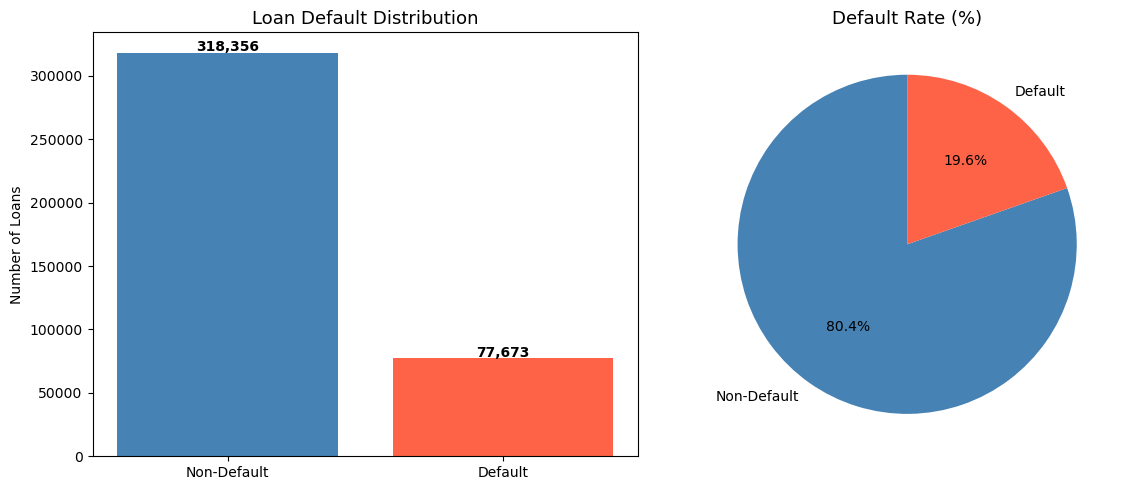

In [ ]:
# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Non-Default', 'Default'], counts.values, color=['steelblue', 'tomato'])
axes[0].set_title('Loan Default Distribution', fontsize=13)
axes[0].set_ylabel('Number of Loans')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=['Non-Default', 'Default'],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Default Rate (%)', fontsize=13)

plt.tight_layout()
plt.savefig('default_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

1.6 Key Features Analysis

Exploring how loan amount, interest rate, annual income and loan grade relate to default risk.

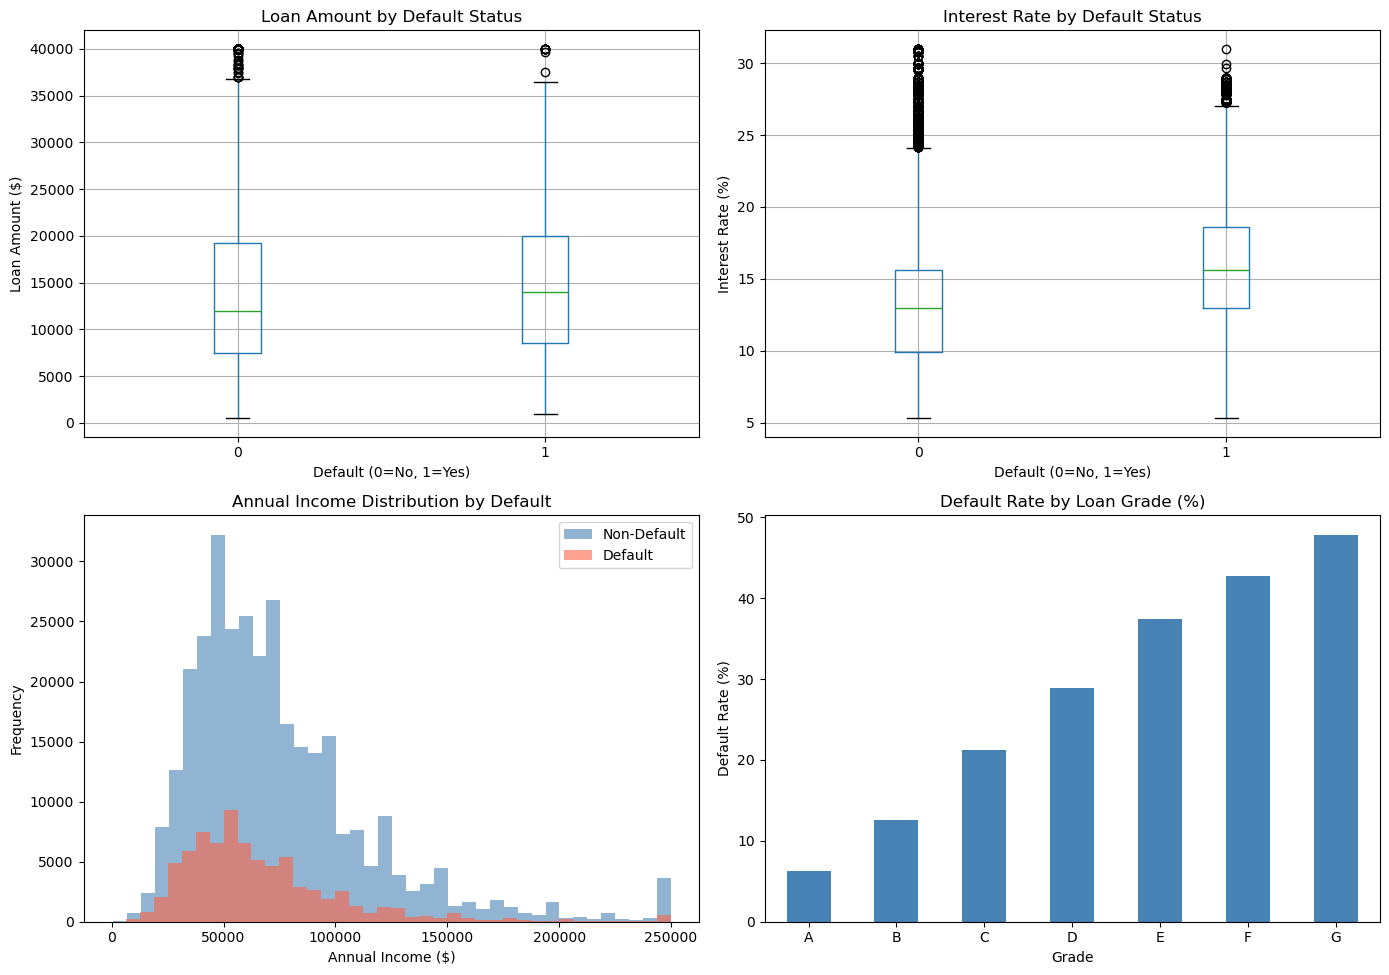

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Loan amount by default
df.boxplot(column='loan_amnt', by='default', ax=axes[0,0])
axes[0,0].set_title('Loan Amount by Default Status')
axes[0,0].set_xlabel('Default (0=No, 1=Yes)')
axes[0,0].set_ylabel('Loan Amount ($)')
plt.sca(axes[0,0]); plt.title('Loan Amount by Default Status')

# 2. Interest rate by default
df.boxplot(column='int_rate', by='default', ax=axes[0,1])
axes[0,1].set_title('Interest Rate by Default Status')
axes[0,1].set_xlabel('Default (0=No, 1=Yes)')
axes[0,1].set_ylabel('Interest Rate (%)')
plt.sca(axes[0,1]); plt.title('Interest Rate by Default Status')

# 3. Annual income by default (capped at 99th percentile)
inc_cap = df['annual_inc'].quantile(0.99)
df_plot = df.copy()
df_plot['annual_inc'] = df_plot['annual_inc'].clip(upper=inc_cap)
df_plot[df_plot['default']==0]['annual_inc'].plot(
    kind='hist', bins=40, ax=axes[1,0], alpha=0.6, color='steelblue', label='Non-Default')
df_plot[df_plot['default']==1]['annual_inc'].plot(
    kind='hist', bins=40, ax=axes[1,0], alpha=0.6, color='tomato', label='Default')
axes[1,0].set_title('Annual Income Distribution by Default')
axes[1,0].set_xlabel('Annual Income ($)')
axes[1,0].legend()

# 4. Default rate by grade
grade_default = df.groupby('grade')['default'].mean() * 100
grade_default.sort_index().plot(kind='bar', ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Default Rate by Loan Grade (%)')
axes[1,1].set_xlabel('Grade')
axes[1,1].set_ylabel('Default Rate (%)')
axes[1,1].tick_params(axis='x', rotation=0)

plt.suptitle('')
plt.tight_layout()
plt.savefig('key_features.png', dpi=150, bbox_inches='tight')
plt.show()

1.7 Correlation Heatmap

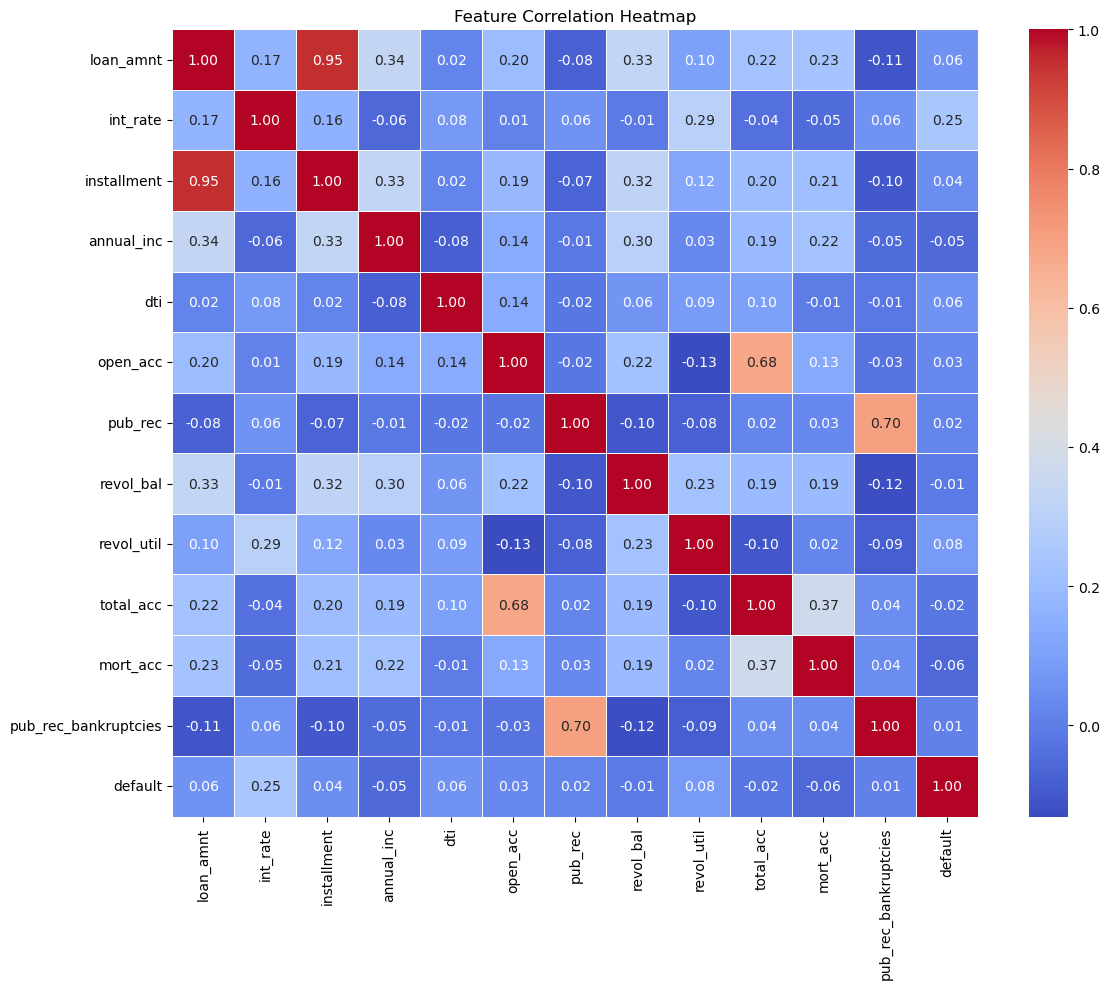

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Required for np.number

# Check if 'df' DataFrame exists in the global scope
if 'df' not in globals():
    print("Error: DataFrame 'df' is not defined.")
    print("Please ensure that all cells from '1.3 Loading the Dataset' through '2.1 Prepare Data' have been executed.")
else:
    plt.figure(figsize=(12, 10))
    sns.heatmap(df.select_dtypes(include=[np.number]).corr(),
                cmap="coolwarm",
                annot=True,
                fmt='.2f',
                linewidths=0.5)
    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()
    plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing


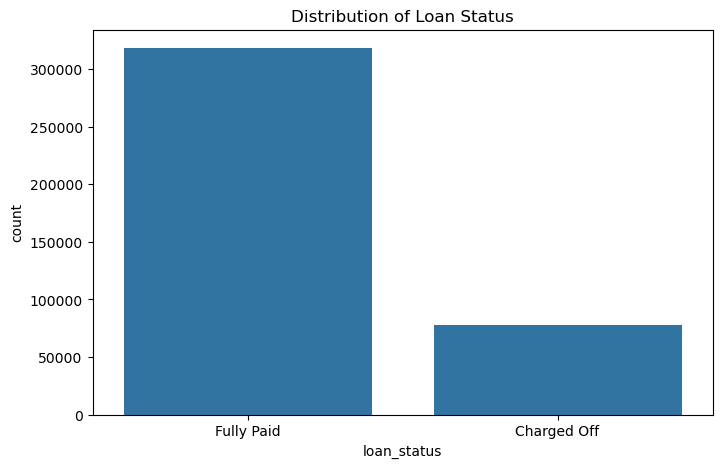

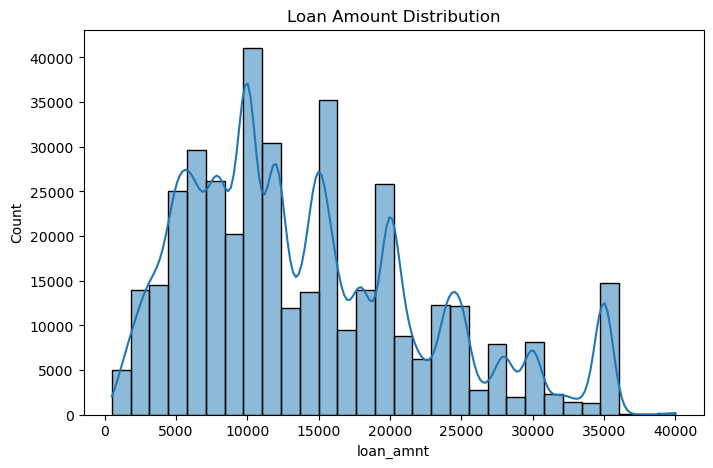

In [ ]:
if 'address' in df.columns:
    df.drop(['address'], axis=1, inplace=True)


cols_to_drop = ['issue_d', 'earliest_cr_line', 'emp_title', 'title']
df.drop(columns=[c for c in cols_to_drop if c in df.columns], inplace=True)


for col in df.columns:
    if df[col].dtype in [np.float64, np.int64]:
        df[col] = df[col].fillna(df[col].mean())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


plt.figure(figsize=(8,5))
sns.countplot(x='loan_status', data=df)
plt.title('Distribution of Loan Status')
plt.show()


plt.figure(figsize=(8,5))
sns.histplot(df['loan_amnt'], bins=30, kde=True)
plt.title('Loan Amount Distribution')
plt.show()

label_encoder = preprocessing.LabelEncoder()
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = label_encoder.fit_transform(df[col].astype(str))

## Section 2: Model Development

### 2.1 Prepare Data

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder


# 1. Handle missing values as done in earlier EDA, or simplify for ML
# These are the fills from NHhNg0YOOKlO in EDA
df['emp_length'] = df['emp_length'].fillna('Unknown')
df['mort_acc'] = df['mort_acc'].fillna(0)
df['pub_rec_bankruptcies'] = df['pub_rec_bankruptcies'].fillna(0)
df['revol_util'] = df['revol_util'].fillna(df['revol_util'].median())

# Ensure loan_status is present and filter it to only 'Fully Paid' and 'Charged Off'
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])]

# Create binary target variable 'default' (0=Non-Default, 1=Default)
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)

# Drop columns not useful for modelling, including the original 'loan_status'
# and others that were identified or are redundant/problematic for ML.
# Combining lists from Ku7mzIzpojg2 and 7kqo_Fyeq05X's original content
cols_to_drop_final = ['emp_title', 'title', 'address',
                      'issue_d', 'earliest_cr_line', 'loan_status']
df = df.drop(columns=[c for c in cols_to_drop_final if c in df.columns], errors='ignore')

# Encode remaining categorical columns into numbers
le = LabelEncoder()
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print(df.shape)

(0, 22)


Train Test Split

In [ ]:
# Separate features from target variable
X = df.drop("default", axis=1)  # All columns except default are input features
y = df["default"]               # Default column is the prediction target

In [ ]:
print(X.shape)
print(y.shape)
print(X.isnull().sum().sum())
print(y.isnull().sum())

(0, 21)
(0,)
0
0


In [ ]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,   # 20% of data used for testing
    random_state=42  # Ensures reproducibility
)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

### 2.2 Logistic Regression

Logistic Regression estimates the probability of loan default using a linear
decision boundary. It is widely used in credit scoring due to its simplicity
and regulatory transparency.

In [ ]:
# Create and train Logistic Regression model
log_model = LogisticRegression(max_iter=1000)  # max_iter ensures convergence
log_model.fit(X_train, y_train)

2.3 Decision Tree

A Decision Tree splits data based on feature thresholds to create decision rules. It is highly interpretable but can overfit — max_depth is used to control this.

In [ ]:
# Create and train Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,     # Limits depth to prevent overfitting
    random_state=42
)
dt_model.fit(X_train, y_train)

2.4 Random Forest

Random Forest builds multiple decision trees and combines their predictions. It reduces overfitting and handles complex relationships in credit risk data.

In [ ]:
# Create and train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,  # Number of decision trees
    max_depth=10,      # Limits tree depth to avoid overfitting
    random_state=42
)
rf_model.fit(X_train, y_train)

2.5 Improve Random Forest with Hyperparameter Tuning

In [ ]:
# Use a sample to speed up GridSearch on large dataset
X_sample, _, y_sample, _ = train_test_split(
    X_train, y_train,
    train_size=0.2,  # Use only 20% of training data to save time
    random_state=42
)

# Define parameter grid to search
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15],
    "min_samples_split": [2, 5]
}

# Initialize GridSearch
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,               # 3-fold cross validation
    scoring="roc_auc",  # Optimise for AUC metric
    n_jobs=-1           # Use all CPU cores
)

# Train on sample
grid_search.fit(X_sample, y_sample)

# Get best model — retrain on full training data
best_rf = grid_search.best_estimator_
best_rf.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("✓ Tuned Random Forest ready")

### 2.6 Model Training & Evaluation

All four models are trained and evaluated using the same pipeline for consistency.
Performance is measured using Accuracy, Precision, Recall, F1-Score and ROC-AUC.

In [ ]:
from sklearn.metrics import roc_auc_score, classification_report

# Define all models in one dictionary
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost":             XGBClassifier(n_estimators=100, learning_rate=0.1, eval_metric='logloss')
}

# Store results for comparison table later
results = []

print("=== MODEL RESULTS ===")

for name, clf in models.items():

    # Train model
    clf.fit(X_train, y_train)

    # Predictions
    y_pred  = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print(f"\n--- {name} ---")
    print(f"Accuracy:  {acc*100:.2f}%")
    print(f"ROC-AUC:   {auc:.4f}")
    print(classification_report(y_test, y_pred,
                                 target_names=['Non-Default', 'Default']))

    # Save results
    results.append({
        'Model':    name,
        'Accuracy': round(acc, 4),
        'ROC-AUC':  round(auc, 4)
    })

### 2.7 Confusion Matrices

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (name, clf) in enumerate(models.items()):
    y_pred = clf.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm,
                annot=True,
                fmt='d',
                cmap='Blues',
                ax=axes[i],
                xticklabels=['Non-Default', 'Default'],
                yticklabels=['Non-Default', 'Default'])

    axes[i].set_title(f'Confusion Matrix: {name}', fontsize=12)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.8 ROC Curve Comparison

In [ ]:
plt.figure(figsize=(9, 6))

for name, clf in models.items():
    y_proba = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1], [0,1], 'k--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.9 Model Comparison Summary Table

In [ ]:
results_df = pd.DataFrame(results).set_index('Model')
print(results_df)